<a href="https://colab.research.google.com/github/jess22jess/SIMULACI-N-II/blob/main/Modelo_SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo SIR con Metropolis

Arcos Gutiérrez Jessica Beatriz

----

**Introducción**:

El modelo SIR se utiliza para describir la propagación de una enfermedad infecciosa en una población cerrada mediante un sistema de ecuaciones diferenciales ordinarias no lineales.

El sistema se define como:

* $\frac{dS}{dt} = -\beta \frac{S I}{N} $

* $\frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I $

* $\frac{dR}{dt} = \gamma I$

Donde $\beta$ es la tasa de transmisión y $\gamma$ es la tasa de recuperación.

La dificultad es que no conocemos los valores exactos de estos parámetros.

Para resolver esto, utilizamos el algoritmo de Metropolis-Hastings, donde el enfoque bayesiano nos permite no solo encontrar el valor más probable de los parámetros ($\beta,\gamma$), sino también cuantificar la incertidumbre de nuestras estimaciones mediante distribuciones de probabilidad posteriores.



Proyecto: Ajuste de parámetros del moelo SIR

1. Graficar datos.
2. Programar la solución numérica del modelo SIR, con parámetros libres.
3. Plantear un ajuste por mínimos cuadrados, X(a,b).
4. Usar el método MCMC (Metropolis Hastings) para optimizar X.
5. Replantear con PyMC el enfoque bayesiano.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# PARTE 1. Graficar Datos

Datos de la tabla de Influenza en la boarding school

In [ ]:
t = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])
I_t = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

Creamos la gráfica de los datos que se nos proporcionaron.

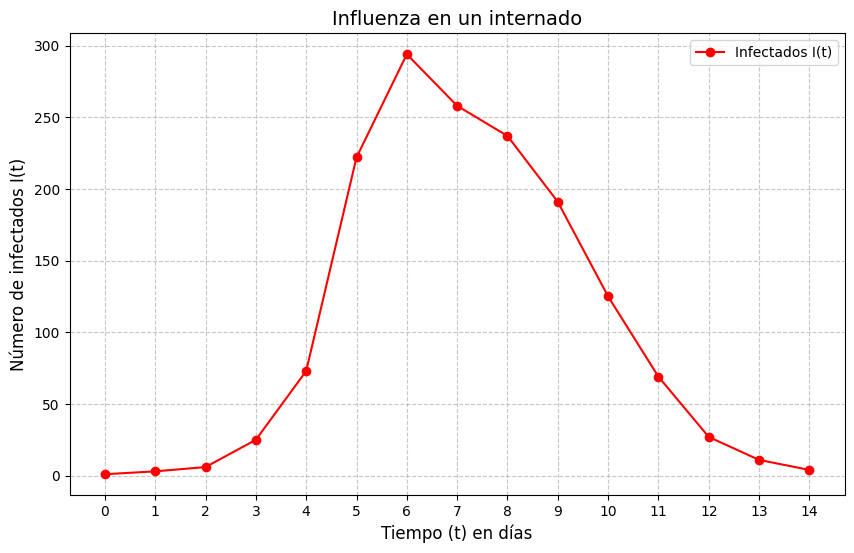

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(t, I_t, marker='o', linestyle='-', color='red', label='Infectados I(t)')
plt.title('Influenza en un internado', fontsize=14)
plt.xlabel('Tiempo (t) en días', fontsize=12)
plt.ylabel('Número de infectados I(t)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7) # Cuadrícula
plt.xticks(t) # Fuerza a que se muestren todos los números enteros en el eje X
plt.legend()

plt.show()

# PARTE 2. Programar la Solución Numérica del Modelo SIR con **parámetros libres**

**from scipy.integrate import odeint** : La razón por la cuál usamos esta librería es para crear una función que teniendo **a** y **b** valores, pueda resolver las ecuaciones diferenciales.

De este modo se nos devolvera la cantidad de infectados I en cada tiempo t.

**from scipy.optimize import minimize** : Para lo que nos sirve esta librería es para dejar **a** y **b** como parámetros libres y que aún con ello pueda encontrar los valores que *minimicen el error*.

In [ ]:
from scipy.integrate import odeint
from scipy.optimize import minimize

Tomamos N igual a 763, dónde N = S + I + R

Para t=0 e I=1

NOTA: Aún no entiendo por qué debemos tomar N=763

In [ ]:
N = 763

Es la función principal del método


In [ ]:
def deriv(Y, t, N, a, b):
    S, I, R = Y
    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I
    return dSdt, dIdt, dRdt

Condiciones iniciales: S0 = N-1, I0 = 1, R0 = 0

ret es donde vamos a resolver las ecuaciones diferenciales

Damos return I porque nos interesa comparar los infectados.

In [ ]:
def resolver_modelo(params, t, N):
    a, b = params
    y0 = [N - 1, 1, 0]
    ret = odeint(deriv, y0, t, args=(N, a, b))
    S, I, R = ret.T
    return I

En la función el parámetro params son los valores de a y b que el optimizador está probando.

Y el error serán la suma de las diferencias al cuadrado.

In [ ]:
def funcion_error(params, t, datos_reales, N):
    I_modelo = resolver_modelo(params, t, N)
    error = np.sum((I_modelo - datos_reales)**2)
    return error

**Añadir nota explicando bien este paso**

In [ ]:
valores_iniciales = [0.002, 0.5]
limites = [(0.0001, 1), (0.0001, 1)]

In [ ]:
resultado = minimize(funcion_error, valores_iniciales, args=(t, I_t, N), bounds=limites)

Extraemos los parámetros óptimos encontrados de a y de b.

In [ ]:
a_optimo, b_optimo = resultado.x

In [ ]:
print(f"Parámetros encontrados: a = {a_optimo:.5f}, b = {b_optimo:.5f}")

Parámetros encontrados: a = 0.00218, b = 0.44522


In [ ]:
I_ajustado = resolver_modelo([a_optimo, b_optimo], t, N)

Gráfica

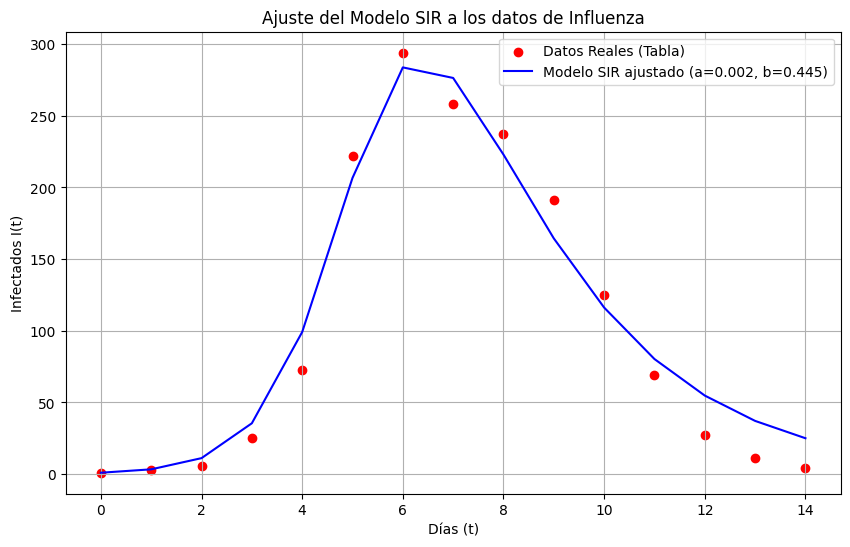

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(t, I_t, color='red', label='Datos Reales (Tabla)')
plt.plot(t, I_ajustado, color='blue', label=f'Modelo SIR ajustado (a={a_optimo:.3f}, b={b_optimo:.3f})')
plt.title('Ajuste del Modelo SIR a los datos de Influenza')
plt.xlabel('Días (t)')
plt.ylabel('Infectados I(t)')
plt.legend()
plt.grid(True)
plt.show()

Nota del final de la clase:

Esto es para la parte de mínimos cuadrados

$X^2$(a,b)= $\frac{(E-O)^2}{E}$